- Github repository: https://github.com/Simen03/simen03-ind320-app 
- Streamlit app: https://simen03-ind320-app-hkg3slagiyz8dtmwljxdtd.streamlit.app/
- Link to video: 

### AI usage

### Log


### Imports

In [1]:
import io
import sys
import tomllib
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import requests
from pymongo import MongoClient
from river import preprocessing, linear_model, optim, time_series

sys.path.append("..")                                    
from modules.NVE_API import fetch_reservoirs, select_area  
from modules.weather import download_weather


2026-11-17 14:05:49.102 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


### Exchange rates from Norges Bank

In [2]:
NB_URL = "https://data.norges-bank.no/api/data/EXR/B.{currencies}.NOK.SP"

def download_exchange_rates(currencies=("EUR", "USD"), start="2015-01-01", end=None):
    """Download daily exchange rates (NOK per 1 unit of foreign currency) from Norges Bank.

    currencies: tuple of currency codes, e.g. ("EUR", "USD")
    start, end: period as 'YYYY-MM-DD' (end defaults to today)
    Returns a DataFrame with one column per currency, indexed by date (business days only).
    """
    end = end or pd.Timestamp.today().strftime("%Y-%m-%d")
    params = {
        "format": "csv",
        "startPeriod": start,
        "endPeriod": end,
        "locale": "en",             
    }
    # '+' joins several currencies into one request
    url = NB_URL.format(currencies="+".join(currencies))
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()     

    # The API returns a semicolon-separated CSV with one row per date and currency
    raw = pd.read_csv(io.StringIO(response.text), sep=";")

    # Long -> wide: one column per currency (EUR, USD), one row per date
    rates = raw.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")
    rates.index = pd.to_datetime(rates.index)
    rates.index.name = "date"
    rates.columns.name = None
    return rates.astype(float).sort_index()

In [3]:
# Test the function: download EUR and USD from 2015 until today and show the last rows
rates = download_exchange_rates()
rates.tail()

,EUR,USD
date,,
2026-11-10,10.6155,9.4663
2026-11-11,10.6145,9.5394
2026-11-12,10.5630,9.5325
2026-11-13,10.5695,9.5634
2026-11-16,10.5740,9.6005


In [4]:
# Summary statistics: number of business days, range of the rates and missing values
print("Number of business days:", len(rates))
print("Period:", rates.index.min().date(), "to", rates.index.max().date())
print("Missing values:\n", rates.isna().sum())
rates.describe()

Number of business days: 2989
Period: 2015-01-02 to 2026-11-16
Missing values:
 EUR    0
USD    0
dtype: int64


,EUR,USD
count,2989.000000,2989.000000
mean,10.307945,9.207499
std,0.963555,1.005008
min,8.327500,7.359300
25%,9.522800,8.387000
50%,10.126800,8.923400
75%,11.268500,10.095200
max,12.316500,11.481700


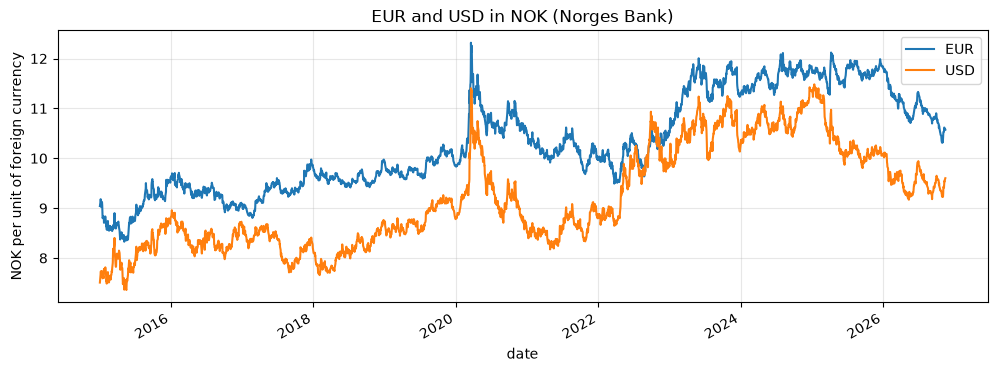

In [5]:
# Plot both currencies over time to check that the downloaded series look reasonable
ax = rates.plot(figsize=(12, 4), title="EUR and USD in NOK (Norges Bank)")
ax.set_ylabel("NOK per unit of foreign currency")
ax.grid(alpha=0.3)

### Time zones in the four different data sources

In [6]:
# Magasinstatistikk: weekly reservoir data from NVE
df = fetch_reservoirs()
print(df[["date_Id", "iso_year", "iso_week", "next_publication_date"]].head())
print("Data type:", df["date_id"].dtype, "| time zone:", df["date_id"].dt.tz)
print("Weekdays in date_Id:", df["date_id"].dt.day_name().value_counts().to_dict())

      date_Id  iso_year  iso_week next_publication_date
0  2020-11-15      2020        46   2020-11-25T13:00:00
1  2011-08-28      2011        34   0001-01-01T00:00:00
2  1998-07-05      1998        27   0001-01-01T00:00:00
3  2011-03-27      2011        12   0001-01-01T00:00:00
4  2017-11-05      2017        44   0001-01-01T00:00:00
Data type: datetime64[us] | time zone: None
Weekdays in date_Id: {'Sunday': 14958}


In [7]:
# ENTSO-E cross-border flows, stored in MongoDB in part 2

secrets = tomllib.load(open("../.streamlit/secrets.toml", "rb"))
coll = MongoClient(secrets["MONGO_uri"])["ind320"]["crossborder_flow"]
flows = pd.DataFrame(list(coll.find({"connection": "NO_2-DE_LU"}, {"_id": 0})))

print(flows["time"].head(3))
print("Data type:", flows["time"].dtype, "| time zone:", flows["time"].dt.tz)

0   2024-10-18 22:00:00
1   2024-10-18 22:00:00
2   2024-10-18 23:00:00
Name: time, dtype: datetime64[us]
Data type: datetime64[us] | time zone: None


In [8]:
# open-meteo: hourly ERA5 data for NO3 in 2025, downloaded with timezone="Europe/Oslo"
weather = download_weather("NO3", "2025-01-01", "2025-12-31", n_locations=3)

print(weather.index[:3])
print("Time zone:", weather.index.tz)
print("First time stamp in Oslo time:", weather.index[0].tz_convert("Europe/Oslo"))

DatetimeIndex(['2024-12-31 23:00:00+00:00', '2025-01-01 00:00:00+00:00',
               '2025-01-01 01:00:00+00:00'],
              dtype='datetime64[s, UTC]', freq=None)
Time zone: UTC
First time stamp in Oslo time: 2025-01-01 00:00:00+01:00


In [9]:
# Norges Bank: daily exchange rates
print(rates.index[:5])
print("Time zone:", rates.index.tz)
print("Weekdays:", rates.index.day_name().value_counts().to_dict())

DatetimeIndex(['2015-01-02', '2015-01-05', '2015-01-06', '2015-01-07',
               '2015-01-08'],
              dtype='datetime64[us]', name='date', freq=None)
Time zone: None
Weekdays: {'Tuesday': 610, 'Wednesday': 609, 'Friday': 597, 'Thursday': 587, 'Monday': 586}


### Findings

| Source | Resolution | Time stamp | Time zone |
|---|---|---|---|
| Magasinstatistikk | Weekly | Date only | Norwegian local dates |
| ENTSO-E | Hourly | Date and time | UTC, stored without time zone information in Cassandra/MongoDB |
| open-meteo | Hourly | Date and time | UTC, the timezone parameter only decides where days start |
| Norges Bank | Daily, business days | Date only | Norwegian dates, weekends and holidays missing |

Main differences:
- **Dates vs. times:** Magasinstatistikk and Norges Bank only have dates, while ENTSO-E and open-meteo have hourly time stamps.
- **UTC vs. local time:** the hourly sources are in UTC. Norway is UTC+1 in winter and UTC+2 in summer,
  so a "day" or "week" in UTC is shifted 1–2 hours compared to a Norwegian day or week.
- **Period labels:** Magasinstatistikk labels each week by its last day (Sunday).
- **Missing days:** Norges Bank has no values on weekends and public holidays.
- **Hidden UTC:** the ENTSO-E data in MongoDB has no time zone label, so it is easy to mistake it for local time.

The outputs above confirm the findings:
- **Magasinstatistikk:** all 14 958 dates are Sundays, i.e. the last day of the ISO week.
- **ENTSO-E:** the first time stamp in MongoDB is 2024-10-18 22:00. The data was downloaded from midnight
  Norwegian time on 19 October 2024 (summer time, UTC+2), so the stored times are UTC without a time zone label.
  The repeated time stamp is one row for export and one for import.
- **open-meteo:** the first time stamp is 2024-12-31 23:00 UTC, which is midnight on 1 January 2025 in Oslo.
- **Norges Bank:** there are fewer Mondays, Thursdays and Fridays than Tuesdays and Wednesdays,
  because Norwegian public holidays (Easter, Ascension Day, Whit Monday) fall on those days.

### Solution
All sources are aligned to weekly resolution in Norwegian time, with weeks ending on Sunday,
which matches the Magasinstatistikk data:
1. Hourly data in UTC is converted to Europe/Oslo with `tz_convert` before aggregating,
   so that weeks follow Norwegian midnight. `tz_localize("Europe/Oslo")` is never used on hourly data,
   because the daylight saving time changes create hours that do not exist or exist twice.
2. Hourly and daily data are aggregated with `resample("W-SUN")`, which labels each Monday–Sunday week by its Sunday.
3. Exchange rates are forward-filled over weekends and holidays before taking the weekly mean.
4. Finally the time zone information is removed, so all sources have the same naive Sunday dates as Magasinstatistikk.

In [10]:
def weekly_oslo(series_or_df, how="mean", source_tz=None):
    """Aggregate an hourly or daily time series to weeks ending on Sunday, in Norwegian time.

    how:       aggregation per week ('mean' for levels such as temperature, 'sum' for amounts such as precipitation)
    source_tz: time zone of a naive index (e.g. 'UTC' for the ENTSO-E data from MongoDB); None if already tz-aware
    """
    s = series_or_df.copy()
    if source_tz is not None:                      # naive time stamps with a known time zone
        s.index = s.index.tz_localize(source_tz)
    if s.index.tz is not None:                     # tz-aware -> Norwegian time
        s.index = s.index.tz_convert("Europe/Oslo")
    weekly = s.resample("W-SUN").agg(how)          # Monday–Sunday weeks, labelled by the Sunday
    if weekly.index.tz is not None:                # drop time zone -> same format as Magasinstatistikk
        weekly.index = weekly.index.tz_localize(None)
    return weekly.rename_axis("week")

In [11]:
# Bring all four sources to the same weekly time axis (2025 as an example)

# Magasinstatistikk: already weekly with Sunday dates
fill_w = select_area(df, "EL", 3)["filling_level"].loc["2025"].rename("filling_level")

# open-meteo: UTC -> Oslo, mean temperature and total precipitation per week
temp_w = weekly_oslo(weather["temperature_2m"], how="mean").rename("temperature")
prec_w = weekly_oslo(weather["precipitation"], how="sum").rename("precipitation")

# ENTSO-E: naive UTC from MongoDB -> Oslo, mean flow per week
flows_exp = flows[flows["direction"] == "export"].set_index("time")["mw"]
flow_w = weekly_oslo(flows_exp, how="mean", source_tz="UTC").rename("export_MW")

# Norges Bank: fill weekends/holidays with the last known rate, then weekly mean
rates_daily = rates.asfreq("D").ffill()
rates_w = weekly_oslo(rates_daily, how="mean")

combined = pd.concat([fill_w, temp_w, prec_w, flow_w, rates_w], axis=1, sort=True).loc["2025"]
combined.head(10)

,filling_level,temperature,precipitation,export_MW,EUR,USD
2025-01-05,0.833894,-5.806167,25.366667,743.210476,11.755971,11.360043
2025-01-12,0.790692,-4.551702,11.400001,635.066667,11.745357,11.368571
2025-01-19,0.810005,4.638476,40.666668,1284.807381,11.729357,11.418057
2025-01-26,0.781375,0.473000,20.900000,1099.589762,11.759286,11.286357
2025-02-02,0.739880,-0.234440,6.266667,998.198810,11.762843,11.290571
2025-02-09,0.705416,0.980937,31.400000,1249.819762,11.662514,11.257257
2025-02-16,0.656979,-2.800909,6.133334,1192.512143,11.640143,11.186929
2025-02-23,0.620425,0.447901,13.733334,1085.392381,11.632214,11.124929
2025-03-02,0.594338,3.951175,53.299999,1242.176905,11.694829,11.189900
2025-03-09,0.608521,4.234905,74.700005,663.175952,11.759429,10.965400


In [12]:
# Check: all sources share the same Sunday dates, and there are no unexpected gaps
print("Weekdays in the combined index:", combined.index.day_name().unique().tolist())
print("Missing values per column:\n", combined.isna().sum())

Weekdays in the combined index: ['Sunday']
Missing values per column:
 filling_level    0
temperature      0
precipitation    0
export_MW        0
EUR              0
USD              0
dtype: int64


## Forecasting the reservoir filling with River (SNARIMAX)

`forecast_filling()` uses River's `SNARIMAX`, an online SARIMAX that learns one week at a time and forecasts
dynamically. The last `horizon` weeks are held out and compared with the actual filling level (MAE).

**Inputs:** region (via `build_weekly()`), model parameters (`p, d, q, sp, sd, sq`, `m = 52`),
history length (`history_years`), horizon (`horizon`) and data sources (`exog`: temperature, precipitation, EUR, USD).

**Time resolution: weekly.** The filling level is only published weekly, so a finer resolution would only make
the function slower without adding information. Weather and exchange rates are aggregated to weeks with `weekly_oslo()`.

**Limitations:** the observed weather is used in the test period, so results with weather are somewhat optimistic.
ENTSO-E data is not used, since it only covers about two years.

In [13]:
def build_weekly(area_type="EL", number=3, start="2017-01-01", end="2025-12-31"):
    """Weekly data set for one Magasinstatistikk area: filling level, weather and exchange rates."""
    region_id = {"EL": f"NO{number}", "VASS": f"VASS {number}", "NO": "Norway"}[area_type]
    hourly = download_weather(region_id, start, end, n_locations=1)
    return pd.concat([
        select_area(df, area_type, number)["filling_level"],                       # target (weekly)
        weekly_oslo(hourly["temperature_2m"], "mean").rename("temperature"),       # weekly mean
        weekly_oslo(hourly["precipitation"], "sum").rename("precipitation"),       # weekly total
        weekly_oslo(download_exchange_rates(start=start, end=end).asfreq("D").ffill(), "mean"),
    ], axis=1, sort=True).loc[start:end].dropna()

weekly = build_weekly("EL", 3)
weekly.tail()

,filling_level,temperature,precipitation,EUR,USD
2025-11-30,0.824069,0.184298,28.100000,11.797971,10.201314
2025-12-07,0.795395,1.253345,6.300000,11.766429,10.102571
2025-12-14,0.774006,1.680131,45.600002,11.824643,10.114886
2025-12-21,0.766409,3.104536,27.100000,11.939686,10.179271
2025-12-28,0.737514,2.199179,32.599998,11.854500,10.063186


In [14]:
def forecast_filling(data, horizon=12, history_years=8, exog=(),
                     p=2, d=1, q=0, m=52, sp=1, sd=0, sq=0):
    """Forecast the weekly filling level with River's SNARIMAX.
    The last `horizon` weeks are held out and used to evaluate the forecast.
    exog: the selected data sources (columns in `data`); an empty tuple gives a model without exogenous variables."""
    exog = list(exog)
    data = data.iloc[-(history_years * 52 + horizon):]      # chosen history + the test period
    train, test = data.iloc[:-horizon], data.iloc[-horizon:]

    # Exogenous variables as one dict per week (empty dicts if no data sources are selected)
    x_train = train[exog].to_dict("records") if exog else [{}] * len(train)
    x_test = test[exog].to_dict("records") if exog else [{}] * horizon

    # Learn one week at a time (online learning)
    model = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq)
    for y, x in zip(train["filling_level"], x_train):
        model.learn_one(y, x)

    # Dynamic forecast: each predicted week is used as input for the next
    forecast = model.forecast(horizon=horizon, xs=x_test)

    result = test[["filling_level"]].assign(forecast=forecast)
    mae = (result["forecast"] - result["filling_level"]).abs().mean()
    return result, mae

In [15]:
# Fixed base settings, so the tests do not change if the defaults of forecast_filling() are changed
base = dict(exog=(), p=2, d=1, q=0, sp=1, history_years=5)

tests = {
    "Base (no exogenous)":     base,
    "Weather":                 {**base, "exog": ("temperature", "precipitation")},
    "Weather + currency":      {**base, "exog": ("temperature", "precipitation", "EUR", "USD")},
    "Non-seasonal AR (sp=0)":  {**base, "sp": 0},
    "AR(1)":                   {**base, "p": 1},
    "AR(3) + MA(1)":           {**base, "p": 3, "q": 1},
    "History 3 years":         {**base, "history_years": 3},
    "History 8 years":         {**base, "history_years": 8},
    "AR(1) + 8 years":         {**base, "p": 1, "history_years": 8},
}

for name, settings in tests.items():
    _, mae = forecast_filling(weekly, **settings)
    print(f"{name:25s} MAE = {mae:.4f}")

Base (no exogenous)       MAE = 0.0614
Weather                   MAE = 0.0782
Weather + currency        MAE = 0.0559
Non-seasonal AR (sp=0)    MAE = 0.0519
AR(1)                     MAE = 0.0615
AR(3) + MA(1)             MAE = 0.0600
History 3 years           MAE = 0.0459
History 8 years           MAE = 0.0693
AR(1) + 8 years           MAE = 0.0680


In [16]:
# Same tests on another period: the 12 weeks up to the end of June 2025 (snow melt and filling season)
for name, settings in tests.items():
    _, mae = forecast_filling(weekly.loc[:"2025-06-30"], **settings)
    print(f"{name:25s} MAE = {mae:.4f}")

Base (no exogenous)       MAE = 0.0593
Weather                   MAE = 0.0667
Weather + currency        MAE = 0.1147
Non-seasonal AR (sp=0)    MAE = 0.1842
AR(1)                     MAE = 0.0467
AR(3) + MA(1)             MAE = 0.0688
History 3 years           MAE = 0.0670
History 8 years           MAE = 0.0297
AR(1) + 8 years           MAE = 0.0466


Text(0, 0.5, 'Filling level')

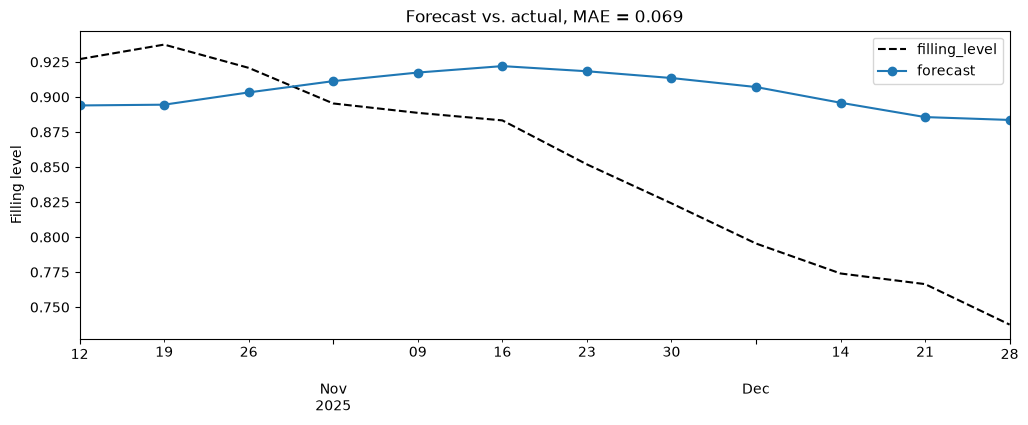

In [17]:
# Plot the forecast of the default settings against the actual values
result, mae = forecast_filling(weekly)
ax = result.plot(figsize=(12, 4), style=["k--", "o-"], title=f"Forecast vs. actual, MAE = {mae:.3f}")
ax.set_ylabel("Filling level")

In [18]:
%%time
# Run time of one forecast with the default settings (weekly data, 5 years of history)
_ = forecast_filling(weekly)

CPU times: total: 15.6 ms
Wall time: 4.48 ms


### Testing and findings

Each setting was changed one at a time from a fixed base model (AR(2), d=1, seasonal AR with sp=1 and m=52,
5 years of history, no exogenous variables) and tested on two 12-week periods:
end of 2025 (reservoirs emptying) and up to June 2025 (snow melt, reservoirs filling).

| Setting | MAE period 1 | MAE period 2 | Mean |
|---|---|---|---|
| Base (no exogenous) | 0.061 | 0.059 | 0.060 |
| Weather | 0.078 | 0.067 | 0.072 |
| Weather + currency | 0.056 | 0.115 | 0.085 |
| Non-seasonal (sp=0) | 0.052 | 0.184 | 0.118 |
| AR(1) | 0.062 | 0.047 | 0.054 |
| AR(3) + MA(1) | 0.060 | 0.069 | 0.064 |
| History 3 years | 0.046 | 0.067 | 0.056 |
| **History 8 years** | 0.069 | 0.030 | **0.050** |
| AR(1) + 8 years | 0.068 | 0.047 | 0.057 |

- The **seasonal AR term** is the most important part of the model. Without it (sp=0) the error in period 2 is
  three times larger, because the model continues the winter decline instead of capturing the spring filling.
- **Weather and exchange rates did not improve the forecast.** The yearly pattern already captures most of what
  the weather explains, such as the snow melt in spring.
- **8 years of history** gave the lowest mean error, mainly because it was much better during the snow melt.
  Combining it with AR(1) did not improve the result further.
- The best setting varied between the two periods, so testing on more than one period was necessary.
- One forecast takes about 0.1 seconds, so weekly resolution is fast enough for Streamlit.

**Experiences:** I expected the weather variables to be the most important, but the results show that the yearly
pattern matters more. Testing on two periods was important, since the conclusions changed when the second period was added.

**Default in Streamlit:** AR(2), d=1, seasonal AR (sp=1, m=52), 8 years of history, no exogenous variables.

### Shapefiles to GeoJSON for the map
The shapefiles from part 3 are converted to GeoJSON, which the map in the Streamlit app can read directly.
The VASS regions are merged as before (East = RS + RØ, North = RM + RN). The polygons are converted to
longitude/latitude (EPSG:4326) and simplified to about 1 km precision, which makes the files much smaller
and the map faster, without visible changes at the zoom level used in the app.

In [19]:
# Read the shapefiles from part 3 (EPSG:25833, UTF-8 so that "RØ" is read correctly)
el = gpd.read_file("../data/Budområder/Budområder.shp", encoding="utf-8")
vass = gpd.read_file("../data/NVE_Region/NVE_Region.shp", encoding="utf-8")

# Price areas: "NO 1" -> area number 1 and id "NO1"
el["number"] = el["budomr"].str[-1].astype(int)
el["region_id"] = "NO" + el["number"].astype(str)

# Water areas: merge the NVE regions into the three VASS areas used in Magasinstatistikk
vass_map = {"RS": 1, "RØ": 1, "RV": 2, "RM": 3, "RN": 3}
vass["number"] = vass["REGION"].map(vass_map)
vass = vass[["number", "geometry"]].dissolve(by="number").reset_index()
vass["region_id"] = "VASS " + vass["number"].astype(str)

# Save as GeoJSON in longitude/latitude, simplified to ~1 km (0.01 degrees) to keep the files small
for gdf, name in [(el, "price_areas"), (vass, "water_areas")]:
    out = gdf[["region_id", "number", "geometry"]].to_crs(epsg=4326)
    out["geometry"] = out.geometry.simplify(0.01, preserve_topology=True)
    out.to_file(f"../data/{name}.geojson", driver="GeoJSON")
    print(name, len(out), "areas")

price_areas 5 areas
water_areas 3 areas
